<a href="https://colab.research.google.com/github/jatinkumar-creator/machine-learning-portfolio/blob/main/06_Ensemble_Learning/notebooks/02_Gradient_Boosting_and_XGBoost.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [34]:
#Import libraries
import numpy as np
import pandas as pd

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

In [35]:
#Load dataset
iris = load_iris()

X = iris.data
y = iris.target

print("Dataset shape:", X.shape)
print("Target shape:", y.shape)

Dataset shape: (150, 4)
Target shape: (150,)


In [36]:
#Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [37]:
#Create Gradient Boosting model
gb_model = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

gb_model.fit(X_train, y_train)

GradientBoostingClassifier(random_state=42)

In [38]:
#Make predictions
gb_pred = gb_model.predict(X_test)

print("Predictions:", gb_pred)

Predictions: [0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 2 1 0 2 0]


In [39]:
#Evaluate model
gb_accuracy = accuracy_score(y_test, gb_pred)

print("Gradient Boosting Accuracy:", gb_accuracy)

print("\nClassification Report:")
print(classification_report(y_test, gb_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, gb_pred))

Gradient Boosting Accuracy: 0.9666666666666667

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      0.90      0.95        10
           2       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30


Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]


In [40]:
#Install XGBoost
%pip install -q xgboost

In [41]:
#Import
from xgboost import XGBClassifier

In [42]:
#Train XGBoost
xgb_model = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    objective="multi:softprob",
    num_class=3,
    eval_metric="mlogloss",
    random_state=42
)

xgb_model.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='mlogloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=3, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=100, n_jobs=None, num_class=3, ...)

In [43]:
#Evaluate XGBoost
xgb_pred = xgb_model.predict(X_test)

xgb_accuracy = accuracy_score(y_test, xgb_pred)

print("XGBoost Accuracy:", xgb_accuracy)

print("\nClassification Report:")
print(classification_report(y_test, xgb_pred))

XGBoost Accuracy: 0.9333333333333333

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       0.90      0.90      0.90        10
           2       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



In [44]:
#Voting Classifier implementation
#Import models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import VotingClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

In [45]:
#Create individual models
logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000))
])

knn_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", KNeighborsClassifier(n_neighbors=5))
])

tree_model = DecisionTreeClassifier(random_state=42)

In [46]:
#Create Voting Classifier
voting_model = VotingClassifier(
    estimators=[
        ("lr", logistic_model),
        ("dt", tree_model),
        ("knn", knn_model)
    ],
    voting="soft"
)

voting_model.fit(X_train, y_train)

VotingClassifier(estimators=[('lr',
                              Pipeline(steps=[('scaler', StandardScaler()),
                                              ('classifier',
                                               LogisticRegression(max_iter=1000))])),
                             ('dt', DecisionTreeClassifier(random_state=42)),
                             ('knn',
                              Pipeline(steps=[('scaler', StandardScaler()),
                                              ('classifier',
                                               KNeighborsClassifier())]))],
                 voting='soft')

In [47]:
#Evaluate Voting Classifier
voting_pred = voting_model.predict(X_test)

voting_accuracy = accuracy_score(y_test, voting_pred)

print("Voting Classifier Accuracy:", voting_accuracy)

Voting Classifier Accuracy: 0.9333333333333333


In [48]:
#Stacking implementation
#Import Stacking
from sklearn.ensemble import StackingClassifier

In [49]:
#Create Stacking Classifier
stacking_model = StackingClassifier(
    estimators=[
        ("lr", logistic_model),
        ("dt", tree_model),
        ("knn", knn_model)
    ],
    final_estimator=LogisticRegression(max_iter=1000),
    cv=5
)

stacking_model.fit(X_train, y_train)

StackingClassifier(cv=5,
                   estimators=[('lr',
                                Pipeline(steps=[('scaler', StandardScaler()),
                                                ('classifier',
                                                 LogisticRegression(max_iter=1000))])),
                               ('dt', DecisionTreeClassifier(random_state=42)),
                               ('knn',
                                Pipeline(steps=[('scaler', StandardScaler()),
                                                ('classifier',
                                                 KNeighborsClassifier())]))],
                   final_estimator=LogisticRegression(max_iter=1000))

In [50]:
#Evaluate Stacking
stacking_pred = stacking_model.predict(X_test)

stacking_accuracy = accuracy_score(y_test, stacking_pred)

print("Stacking Accuracy:", stacking_accuracy)

Stacking Accuracy: 0.9666666666666667


In [51]:
from sklearn.metrics import accuracy_score
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier

# Decision Tree - Define, fit, and predict
tree_model = DecisionTreeClassifier(random_state=42)
tree_model.fit(X_train, y_train)
dt_pred = tree_model.predict(X_test)
dt_accuracy = accuracy_score(y_test, dt_pred)

# Random Forest - Define, fit, and predict
rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)
rf_accuracy = accuracy_score(y_test, rf_pred)

# AdaBoost - Define, fit, and predict
ada_model = AdaBoostClassifier(random_state=42)
ada_model.fit(X_train, y_train)
ada_pred = ada_model.predict(X_test)
ada_accuracy = accuracy_score(y_test, ada_pred)

# Gradient Boosting
gb_pred = gb_model.predict(X_test)
gb_accuracy = accuracy_score(y_test, gb_pred)

# XGBoost
xgb_pred = xgb_model.predict(X_test)
xgb_accuracy = accuracy_score(y_test, xgb_pred)

# Voting Classifier
voting_pred = voting_model.predict(X_test)
voting_accuracy = accuracy_score(y_test, voting_pred)

# Stacking Classifier
stacking_pred = stacking_model.predict(X_test)
stacking_accuracy = accuracy_score(y_test, stacking_pred)

print("All model accuracy values calculated successfully.")

All model accuracy values calculated successfully.


In [52]:
#Model comparison
comparison = pd.DataFrame({
    "Model": [
        "Decision Tree",
        "Random Forest",
        "AdaBoost",
        "Gradient Boosting",
        "XGBoost",
        "Voting Classifier",
        "Stacking Classifier"
    ],
    "Accuracy": [
        dt_accuracy,
        rf_accuracy,
        ada_accuracy,
        gb_accuracy,
        xgb_accuracy,
        voting_accuracy,
        stacking_accuracy
    ]
})

comparison = comparison.sort_values(
    by="Accuracy",
    ascending=False
)

print(comparison)

                 Model  Accuracy
3    Gradient Boosting  0.966667
6  Stacking Classifier  0.966667
0        Decision Tree  0.933333
4              XGBoost  0.933333
2             AdaBoost  0.933333
5    Voting Classifier  0.933333
1        Random Forest  0.900000


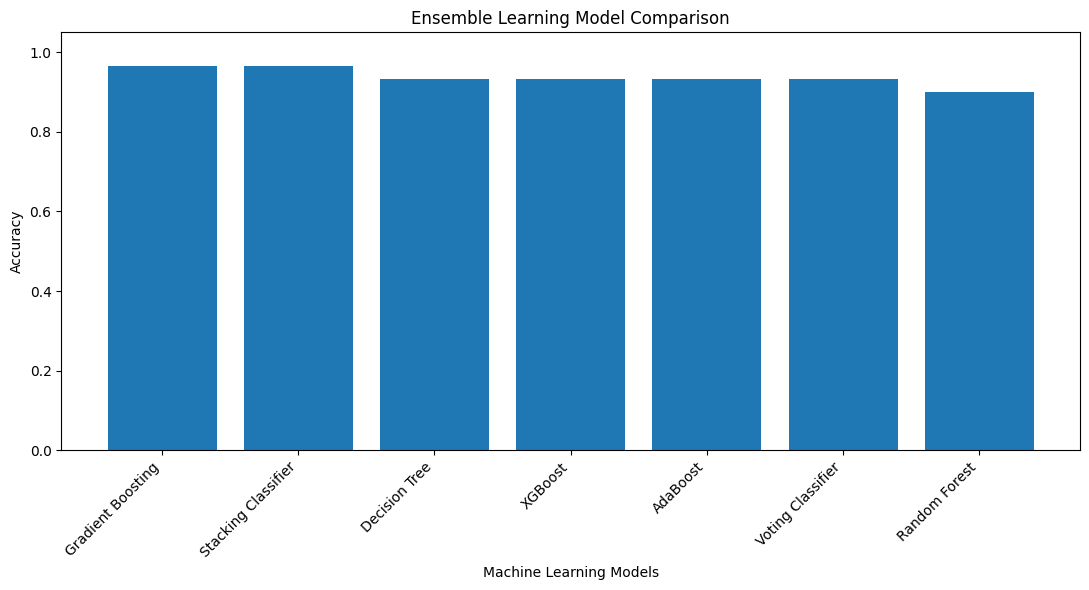

In [53]:
#Visualize model comparison
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 6))

plt.bar(
    comparison["Model"],
    comparison["Accuracy"]
)

plt.title("Ensemble Learning Model Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy")
plt.xticks(rotation=45, ha="right")
plt.ylim(0, 1.05)

plt.tight_layout()
plt.show()